In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial.distance import pdist
from scipy.stats import rankdata
from sklearn.model_selection import train_test_split


PROJECT_ROOT = Path.cwd().parent

REPRESENTATIONS_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "representations"
)

FIGURES_DIR = (
    PROJECT_ROOT
    / "reports"
    / "figures"
)

TABLES_DIR = (
    PROJECT_ROOT
    / "reports"
    / "tables"
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TABLES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

biblioteka pdist racuna udaljenosti izmedju svih razlicitih parova primera.

In [2]:
representations_path = (
    REPRESENTATIONS_DIR
    / "optimized_mlp_test_representations.npz"
)

layer_names = [
    "input",
    "hidden_1",
    "hidden_2",
    "bottleneck"
]

with np.load(representations_path) as saved_data:

    representations = {
        layer_name: saved_data[layer_name]
        for layer_name in layer_names
    }

    labels = (
        saved_data["labels"]
        .ravel()
        .astype(int)
    )

In [3]:
for layer_name, values in representations.items():

    print(
        f"{layer_name}: {values.shape}"
    )

print("Labels:", labels.shape)
print(
    "Raspodela klasa:",
    np.unique(
        labels,
        return_counts=True
    )
)

input: (19868, 168)
hidden_1: (19868, 256)
hidden_2: (19868, 128)
bottleneck: (19868, 16)
Labels: (19868,)
Raspodela klasa: (array([0, 1]), array([17605,  2263]))


Broj jedinstvenih parova za n primera je n(n-1)/2, tako bi ceo test skup racunao oko 197 miliona udaljenosti, zato uzimamo stratifikovani poduzorak kako bi racunanje bilo prihvatljivije i odnos klasa priblizno isti u celom test skupu.

In [4]:
RSA_SAMPLE_SIZE = 2000
RANDOM_STATE = 42

all_indices = np.arange(
    len(labels)
)

rsa_indices, _ = train_test_split(
    all_indices,
    train_size=RSA_SAMPLE_SIZE,
    stratify=labels,
    random_state=RANDOM_STATE
)

In [5]:
sampled_representations = {
    layer_name: values[rsa_indices]
    for layer_name, values
    in representations.items()
}

sampled_labels = labels[
    rsa_indices
]

In [6]:
for layer_name, values in (
    sampled_representations.items()
):

    print(
        f"{layer_name}: {values.shape}"
    )

class_values, class_counts = np.unique(
    sampled_labels,
    return_counts=True
)

print(
    "Klase u RSA poduzorku:",
    dict(
        zip(
            class_values,
            class_counts
        )
    )
)

input: (2000, 168)
hidden_1: (2000, 256)
hidden_2: (2000, 128)
bottleneck: (2000, 16)
Klase u RSA poduzorku: {np.int64(0): np.int64(1772), np.int64(1): np.int64(228)}


Potrebno je ukloniti neaktivne neurone zbog racunanja Pearson-ove korelacije. Dodavanje velikog broja nultih kolona moze promeniti srednje vrednosti, standardne devijacije i korelaciju.

In [7]:
variable_sampled_representations = {}

for layer_name, values in (
    sampled_representations.items()
):

    column_standard_deviations = (
        values.std(axis=0)
    )

    variable_columns = ~np.isclose(
        column_standard_deviations,
        0.0
    )

    number_of_removed_columns = (
        (~variable_columns).sum()
    )

    if not variable_columns.any():
        raise ValueError(
            f"Sloj {layer_name} nema "
            "nijednu dimenziju sa varijacijom."
        )

    variable_sampled_representations[
        layer_name
    ] = values[
        :,
        variable_columns
    ]

    print(
        f"{layer_name}: uklonjeno "
        f"{number_of_removed_columns} "
        f"dimenzija bez varijacije; "
        f"preostalo "
        f"{variable_columns.sum()}"
    )

sampled_representations = (
    variable_sampled_representations
)

input: uklonjeno 19 dimenzija bez varijacije; preostalo 149
hidden_1: uklonjeno 60 dimenzija bez varijacije; preostalo 196
hidden_2: uklonjeno 66 dimenzija bez varijacije; preostalo 62
bottleneck: uklonjeno 5 dimenzija bez varijacije; preostalo 11


Potrebno je proveriti da li neki primer ima konstantan vektor, takav red nema varijaciju, pa ne mozemo racunati njegovu korelaciju sa drugim primerima.

In [8]:
for layer_name, values in (
    sampled_representations.items()
):

    row_standard_deviations = (
        values.std(axis=1)
    )

    constant_rows = np.isclose(
        row_standard_deviations,
        0.0
    )

    number_of_constant_rows = (
        constant_rows.sum()
    )

    print(
        f"{layer_name}: "
        f"{number_of_constant_rows} "
        f"konstantnih redova"
    )

input: 0 konstantnih redova
hidden_1: 0 konstantnih redova
hidden_2: 0 konstantnih redova
bottleneck: 0 konstantnih redova


In [9]:
final_sample_size = len(
    sampled_labels
)

number_of_pairs = (
    final_sample_size
    * (final_sample_size - 1)
    // 2
)

print(
    "Konačan broj RSA primera:",
    final_sample_size
)

print(
    "Broj jedinstvenih parova:",
    number_of_pairs
)

Konačan broj RSA primera: 2000
Broj jedinstvenih parova: 1999000


Representational similarity analysis ispituje kako su pojedinacni primeri medjusobno povezani unutar svakog prostora.<br>
Za svaki prostor, posmatramo udaljenost svakog para primera.<br>
Za svaki sloj se formira matrica reprezentacionih razlicitosti (RDM). <br>
Matrica je simetricna, na dijagonali ima nule, gornji i donji trougao sadrze iste vrednosti, zato ne cuvamo celu matricu.<br>
pdist vraca samo jedinstvene vrednosti iz jednog trougla matrice.

In [10]:
rdm_vectors = {}

for layer_name, values in (
    sampled_representations.items()
):

    print(
        f"Računanje RDM vektora: "
        f"{layer_name}"
    )

    rdm_vector = pdist(
        values.astype(np.float64),
        metric="correlation"
    )

    if not np.isfinite(
        rdm_vector
    ).all():

        raise ValueError(
            f"RDM za sloj {layer_name} "
            f"sadrži NaN ili beskonačne vrednosti."
        )

    rdm_vectors[layer_name] = (
        rdm_vector
    )

    print(
        f"Oblik: {rdm_vector.shape}, "
        f"minimum: {rdm_vector.min():.4f}, "
        f"maksimum: {rdm_vector.max():.4f}, "
        f"prosek: {rdm_vector.mean():.4f}"
    )

Računanje RDM vektora: input
Oblik: (1999000,), minimum: 0.0228, maksimum: 1.3330, prosek: 0.5264
Računanje RDM vektora: hidden_1
Oblik: (1999000,), minimum: 0.0068, maksimum: 1.3470, prosek: 0.5559
Računanje RDM vektora: hidden_2
Oblik: (1999000,), minimum: 0.0000, maksimum: 1.4035, prosek: 0.6143
Računanje RDM vektora: bottleneck
Oblik: (1999000,), minimum: 0.0000, maksimum: 1.6536, prosek: 0.5845


In [11]:
rsa_data_path = (
    REPRESENTATIONS_DIR
    / "rsa_sample_rdm_vectors.npz"
)

np.savez_compressed(
    rsa_data_path,

    sample_indices=rsa_indices,
    labels=sampled_labels,

    input=rdm_vectors["input"],
    hidden_1=rdm_vectors["hidden_1"],
    hidden_2=rdm_vectors["hidden_2"],
    bottleneck=rdm_vectors["bottleneck"]
)

Pearson-ova korelacija se koristi za racunanje udaljenosti izmedju dva primera unutar jednog sloja, meri koliko su dve promenljive povezane linearnim odnosom.<br>
pdist uzima dva primera istog sloja i poredi njihove vektore aktivacija.<br>
Koristimo Spearman-ovu korelaciju da proverimo da li dve promenljive imaju monoton odnos (kada vrednosti jedne rastu, da li vrednosti druge takodje rastu), spearman-ova korelacija zapravo poredi rangove.<br>
npr.<br>
X: 1, 2, 3, 4 <br>
Y: 1, 4, 9, 16 <br>
odnos nije linearan, ali su rangovi isti, najmanji, drugi, treci, najveci.<br>
<br>
Za svaki sloj uzimamo njegov RDM vektor i svakoj udaljenosti dodeljujemo rang.<br>
Ovako rangirane vrednosti nam govore gde se taj par nalazi u odnosu na sve ostale parove.<br>
Ako su rangovi medju slojevima slicni, onda su parovi bliski u jednom prostoru, bliski i u drugom.

In [12]:
ranked_rdm_vectors = {}

for layer_name, rdm_vector in (
    rdm_vectors.items()
):

    print(
        f"Rangiranje RDM vrednosti: "
        f"{layer_name}"
    )

    ranked_rdm_vectors[layer_name] = (
        rankdata(
            rdm_vector,
            method="average"
        )
    )

Rangiranje RDM vrednosti: input
Rangiranje RDM vrednosti: hidden_1
Rangiranje RDM vrednosti: hidden_2
Rangiranje RDM vrednosti: bottleneck


## Funkcija za RSA slicnost<br>
Poredi dva rangirana RDM vektora i vraca broj koji pokazuje koliko dva sloja slicno rasporedjuju iste parove primera.<br>
np.corrcoef racuna pearson-ovu korelaciju nad rangovima.<br>
correlation_matrix[0, 1] je slicnost izmedju dva sloja, [red, kolona]

In [13]:
def rsa_similarity(
    ranked_rdm_x,
    ranked_rdm_y
):

    correlation_matrix = np.corrcoef(
        ranked_rdm_x,
        ranked_rdm_y
    )

    similarity = correlation_matrix[
        0,
        1
    ]

    return float(similarity)

Kompletna RSA matrica.

In [14]:
number_of_layers = len(
    layer_names
)

rsa_matrix = np.zeros(
    (
        number_of_layers,
        number_of_layers
    )
)

for i, first_layer in enumerate(
    layer_names
):

    for j, second_layer in enumerate(
        layer_names
    ):

        rsa_matrix[i, j] = (
            rsa_similarity(
                ranked_rdm_vectors[
                    first_layer
                ],
                ranked_rdm_vectors[
                    second_layer
                ]
            )
        )

In [15]:
rsa_df = pd.DataFrame(
    rsa_matrix,
    index=layer_names,
    columns=layer_names
)

rsa_df.round(4)

,input,hidden_1,hidden_2,bottleneck
input,1.0000,0.4580,0.3067,0.2412
hidden_1,0.4580,1.0000,0.9108,0.7729
hidden_2,0.3067,0.9108,1.0000,0.9036
bottleneck,0.2412,0.7729,0.9036,1.0000


Slicnost sa ulaznim prostorom postepeno opada kako se ide dublje kroz mrezu.<br>
Mreza menja relativni raspored primera, model verovatno reogranizuje primere koji su korisniji za predikciju.<br>
Odnos izmedju skrivenih slojeva je visoka, sto znaci da slicno rangiraju primere. <br>
Najveca slicnost je izmedju drugog skrivenog sloja i bottleneck sloja, sto znaci da gotovo isto rangiraju primere i kompresija sa 128 na 16 dimenzija u velikoj meri cuva reprezentacionu geometriju prethodnog sloja.<br>
Dakle, redosled razlicitosti i slicnosti izmedju primera je veoma slican.

Provera.

In [16]:
print(
    "Dijagonala:",
    np.diag(rsa_matrix)
)

print(
    "Matrica je simetrična:",
    np.allclose(
        rsa_matrix,
        rsa_matrix.T
    )
)

Dijagonala: [1. 1. 1. 1.]
Matrica je simetrična: True


In [17]:
rsa_table_path = (
    TABLES_DIR
    / "rsa_layer_similarity.csv"
)

rsa_df.to_csv(
    rsa_table_path,
    index=True
)

Heatmap RSA matrice.

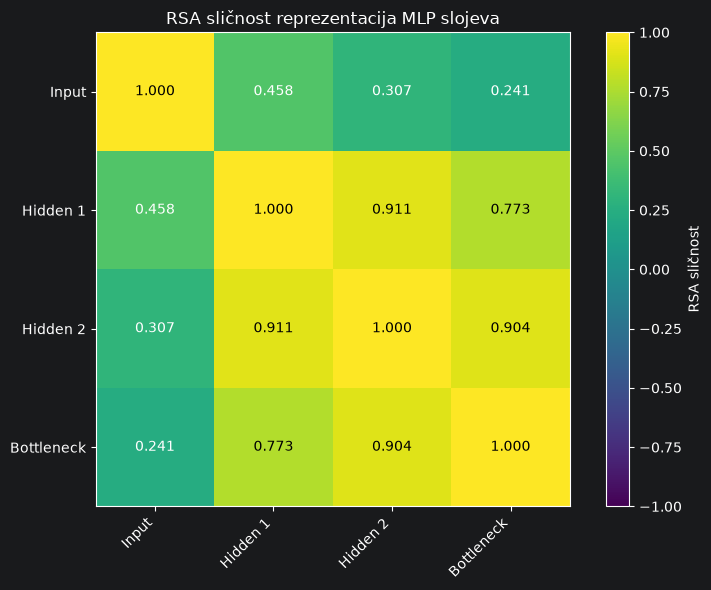

In [18]:
layer_labels = [
    "Input",
    "Hidden 1",
    "Hidden 2",
    "Bottleneck"
]

figure_path = (
    FIGURES_DIR
    / "rsa_layer_similarity.png"
)

fig, ax = plt.subplots(
    figsize=(8, 6)
)

image = ax.imshow(
    rsa_matrix,
    vmin=-1,
    vmax=1
)

ax.set_xticks(
    np.arange(number_of_layers)
)

ax.set_yticks(
    np.arange(number_of_layers)
)

ax.set_xticklabels(
    layer_labels,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(
    layer_labels
)

for row_index in range(
    number_of_layers
):

    for column_index in range(
        number_of_layers
    ):

        value = rsa_matrix[
            row_index,
            column_index
        ]

        text_color = (
            "white"
            if value < 0.5
            else "black"
        )

        ax.text(
            column_index,
            row_index,
            f"{value:.3f}",
            ha="center",
            va="center",
            color=text_color
        )

colorbar = fig.colorbar(
    image,
    ax=ax
)

colorbar.set_label(
    "RSA sličnost"
)

ax.set_title(
    "RSA sličnost reprezentacija MLP slojeva"
)

plt.tight_layout()

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Grafikon slicnosti sa bottleneck-om.

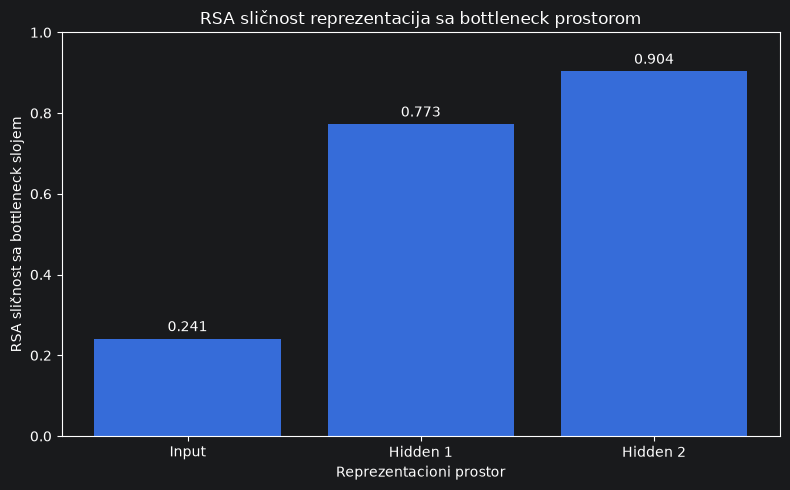

In [19]:
bottleneck_similarities = rsa_df.loc[
    [
        "input",
        "hidden_1",
        "hidden_2"
    ],
    "bottleneck"
]

figure_path = (
    FIGURES_DIR
    / "rsa_similarity_to_bottleneck.png"
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    [
        "Input",
        "Hidden 1",
        "Hidden 2"
    ],
    bottleneck_similarities.values
)

plt.ylim(0, 1)

plt.xlabel("Reprezentacioni prostor")
plt.ylabel("RSA sličnost sa bottleneck slojem")

plt.title(
    "RSA sličnost reprezentacija "
    "sa bottleneck prostorom"
)

plt.bar_label(
    bars,
    fmt="%.3f",
    padding=3
)

plt.tight_layout()

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Podrzana je pretpostavka da slojevi koji su blizi bottleneck-u formiraju reprezentacionu geometriju slicniju bottleneck prostoru.<br>
Obe metode (CKA i RSA) dovode do istog zakljucka: ulazni prostor se znacajno transformise, dok je geometrija dubljih slojeva u velikoj meri ocuvana pri prelasku u bottleneck.

RSA rezultati se zasnivaju na jednom stratifikovanom poduzorku od 2000 test primera. Trenutni slucjani uzorak nije dovoljan za tvrdnju o stabilnosti, te bi ona trebalo biti dodatno proverena ponavljanjem analize vise puta na vise poduzoraka.